In [ ]:
import marimo as mo

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_moons

**Actividad 3 · Red neuronal con una capa oculta**

**Nombre:** Carlos Pulido Rosas

# Red neuronal con una capa oculta

En el script anterior habíamos observado que un solo perceptrón siempre produce una frontera lineal de decisión (clasificación). En este notebook ahora incluiremos una capa oculta con $n_h$ neuronas, es decir


$$2\;\text{entradas}\quad\longrightarrow\quad
n_h\;\text{neuronas ocultas}\quad\longrightarrow\quad
1\;\text{neurona de salida}$$

Cada neurona oculta construye una combinación lineal diferente (o sea, la recta). La función de activación utilizada transforma estas combinaciones y permite que la salida final tenga una frontera de decisión no lineal.

In [ ]:
# widgets de marimo

neuronas = mo.ui.slider(1, 12, value=4, step=1, label="Neuronas ocultas $n_h$")
activacion = mo.ui.dropdown(
    options={"Tangente hiperbólica": "tanh", "ReLU": "relu"},
    value="Tangente hiperbólica",
    label="Activación oculta",
)
ruido = mo.ui.slider(0.02, 0.35, value=0.18, step=0.01, label="Ruido")
learning_rate = mo.ui.slider(0.01, 1.5, value=0.8, step=0.01, label="Learning rate")
iteraciones = mo.ui.slider(200, 10000, value=3000, step=200, label="Iteraciones")

mo.vstack([
    mo.md("### Arquitectura y entrenamiento"),
    mo.hstack([neuronas, activacion]),
    mo.hstack([ruido, learning_rate]),
    iteraciones,
])

Arquitectura y entrenamiento <marimo-slider data-initial-value='4' data-label='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eNeuronas ocultas \u003cmarimo-tex class=\"arithmatex\"\u003e||(n_h||)\u003c/marimo-tex\u003e\u003c/span\u003e\u003c/span\u003e"' data-start='1' data-stop='12' data-step='1' data-steps='[]' data-debounce='false' data-disabled='false' data-orientation='"horizontal"' data-show-value='false' data-include-input='false' data-full-width='false'>

In [ ]:
muestras, etiquetas = make_moons(
    n_samples=250,
    noise=ruido.value,
    random_state=42,
)
X = muestras.T
y = etiquetas.reshape(1, -1)

In [ ]:
mo.md(rf"""
## Propagación hacia adelante (*forward propagation*)

La primera capa calcula:

\[
Z^{{[1]}}=W^{{[1]}}X+b^{{[1]}},\qquad
A^{{[1]}}=g(Z^{{[1]}})
\]

La capa de salida calcula:

\[
Z^{{[2]}}=W^{{[2]}}A^{{[1]}}+b^{{[2]}},\qquad
A^{{[2]}}=\sigma(Z^{{[2]}})
\]

Con \(n_h={neuronas.value}\), las dimensiones son:

| Parámetro o activación | Dimensión |
|---|---:|
| \(X\) | \((2,m)\) |
| \(W^{{[1]}}\) | \(({neuronas.value},2)\) |
| \(b^{{[1]}}\) | \(({neuronas.value},1)\) |
| \(A^{{[1]}}\) | \(({neuronas.value},m)\) |
| \(W^{{[2]}}\) | \((1,{neuronas.value})\) |
| \(b^{{[2]}}\) | \((1,1)\) |
| \(A^{{[2]}}\) | \((1,m)\) |
""")

## Propagación hacia adelante (*forward propagation*)

La primera capa calcula:

\[
Z^{[1]}=W^{[1]}X+b^{[1]},\qquad
A^{[1]}=g(Z^{[1]})
\]

La capa de salida calcula:

\[
Z^{[2]}=W^{[2]}A^{[1]}+b^{[2]},\qquad
A^{[2]}=\sigma(Z^{[2]})
\]

Con \(n_h=4\), las dimensiones son:

| Parámetro o activación | Dimensión |
|---|---:|
| \(X\) | \((2,m)\) |
| \(W^{[1]}\) | \((4,2)\) |
| \(b^{[1]}\) | \((4,1)\) |
| \(A^{[1]}\) | \((4,m)\) |
| \(W^{[2]}\) | \((1,4)\) |
| \(b^{[2]}\) | \((1,1)\) |
| \(A^{[2]}\) | \((1,m)\) |

In [ ]:
# Funciones utilizadas

def sigmoid(Z):
    """
    Función de activación sigmoide
    """
    return 1.0 / (1.0 + np.exp(-np.clip(Z, -500, 500)))

def activation(Z, nombre):
    """
    Aplica la activación elegida en la capa oculta.
    """

    if nombre == "tanh":
        return np.tanh(Z) 
    else:
        return np.maximum(0,Z) # ReLU

def activation_derivative(Z, A, nombre):
    """
    Calcula la derivada de la activación oculta.
    """

    if nombre == "tanh":
        return 1 - A**2
    else:
        return (Z > 0).astype(float)


def initialize_parameters(n_x, n_h, n_y=1, nombre="tanh", semilla=42):
    """
    Inicializa los parámetros del modelo.

    Para tanh utilizamos una escala tipo Xavier; para ReLU, una escala tipo He.
    """
    generador = np.random.default_rng(semilla)

    escala_1 = np.sqrt((2 if nombre == "relu" else 1) / n_x)

    W1 = generador.normal(0, escala_1, (n_h, n_x))
    b1 = np.zeros((n_h, 1))
    W2 = generador.normal(0, np.sqrt(1 / n_h), (n_y, n_h))
    b2 = np.zeros((n_y, 1))

    parameters = {
        "W1": W1,
        "b1": b1,
        "W2": W2,
        "b2": b2
    }

    return parameters

def forward_propagation(X, parameters, nombre):
    """
    Implementa la propagación hacia adelante de las dos capas.
    """

    # parametros, pesos y sesgos
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]

    # capas y sus transformaciones
    Z1 = np.matmul(W1,X) + b1
    A1 = activation(Z1, nombre)
    Z2 = np.matmul(W2,A1) + b2
    A2 = sigmoid(Z2) # salida

    # cache
    cache = {
        "Z1": Z1,
        "A1": A1,
        "Z2":Z2,
        "A2":A2
    }

    return A2, cache

def loss(A2, y):
    """
    Función de pérdida (entropía cruzada binaria)
    """
    A2_segura = np.clip(A2, 1e-10, 1 - 1e-10)

    loss = -np.mean(y * np.log(A2_segura) + (1 - y) * np.log(1 - A2_segura))

    return loss

def backward_propagation(X, y, parameters, cache, nombre):
    """
    Implementa backpropagation aplicando la regla de la cadena.
    """

    m = X.shape[1]
    A1, A2, Z1 = cache["A1"], cache["A2"], cache["Z1"]

    dZ2 = A2 - y
    dW2 = np.matmul(dZ2,A1.T) / m
    db2 = np.sum(dZ2, axis=1, keepdims=True) / m

    dA1 = np.matmul(parameters["W2"].T, dZ2)
    dZ1 = dA1 * activation_derivative(Z1, A1, nombre)
    dW1 = np.matmul(dZ1, X.T) / m
    db1 = np.sum(dZ1, axis=1, keepdims=True) / m

    grads = {
        "dW1":dW1,
        "db1":db1,
        "dW2":dW2,
        "db2":db2
    }

    return grads

def update_parameters(parameters, grads, learning_rate):
    """
    Actualiza los parámetros utilizando descenso del gradiente.
    """

    for indice in (1, 2):
        parameters[f"W{indice}"] -= learning_rate * grads[f"dW{indice}"]
        parameters[f"b{indice}"] -= learning_rate * grads[f"db{indice}"]
    
    return parameters

def nn_model(X, y, n_h=4, nombre="tanh", iterations=3000, learning_rate=0.8):
    """
    Construye y entrena una red neuronal con una capa oculta.
    """
    parameters = initialize_parameters(n_x=X.shape[0],
                                       n_h=n_h,
                                       n_y=y.shape[0],
                                       nombre=nombre)
    costs = []

    # ciclo de entrenamiento
    for i in range(iterations):
        A2, cache = forward_propagation(X=X,
                                        parameters=parameters,
                                        nombre=nombre)
        cost = loss(A2=A2,
                    y=y)
        grads = backward_propagation(X=X,
                                     y=y,
                                     parameters=parameters,
                                     cache=cache, 
                                     nombre=nombre)
        parameters = update_parameters(parameters=parameters,
                                       grads=grads, 
                                       learning_rate=learning_rate)
        if i % 20 == 0:
            costs.append((i, cost))

    return parameters, costs

In [ ]:
# Se corre el entrenamiento de la red neuronal

parameters, costs = nn_model(
    X=X,
    y=y,
    n_h=neuronas.value,
    nombre=activacion.value,
    iterations=iteraciones.value,
    learning_rate=learning_rate.value,
)
A2, cache = forward_propagation(X=X, 
                                parameters=parameters, 
                                nombre=activacion.value)
accuracy = float(np.mean((A2 > 0.5) == y))

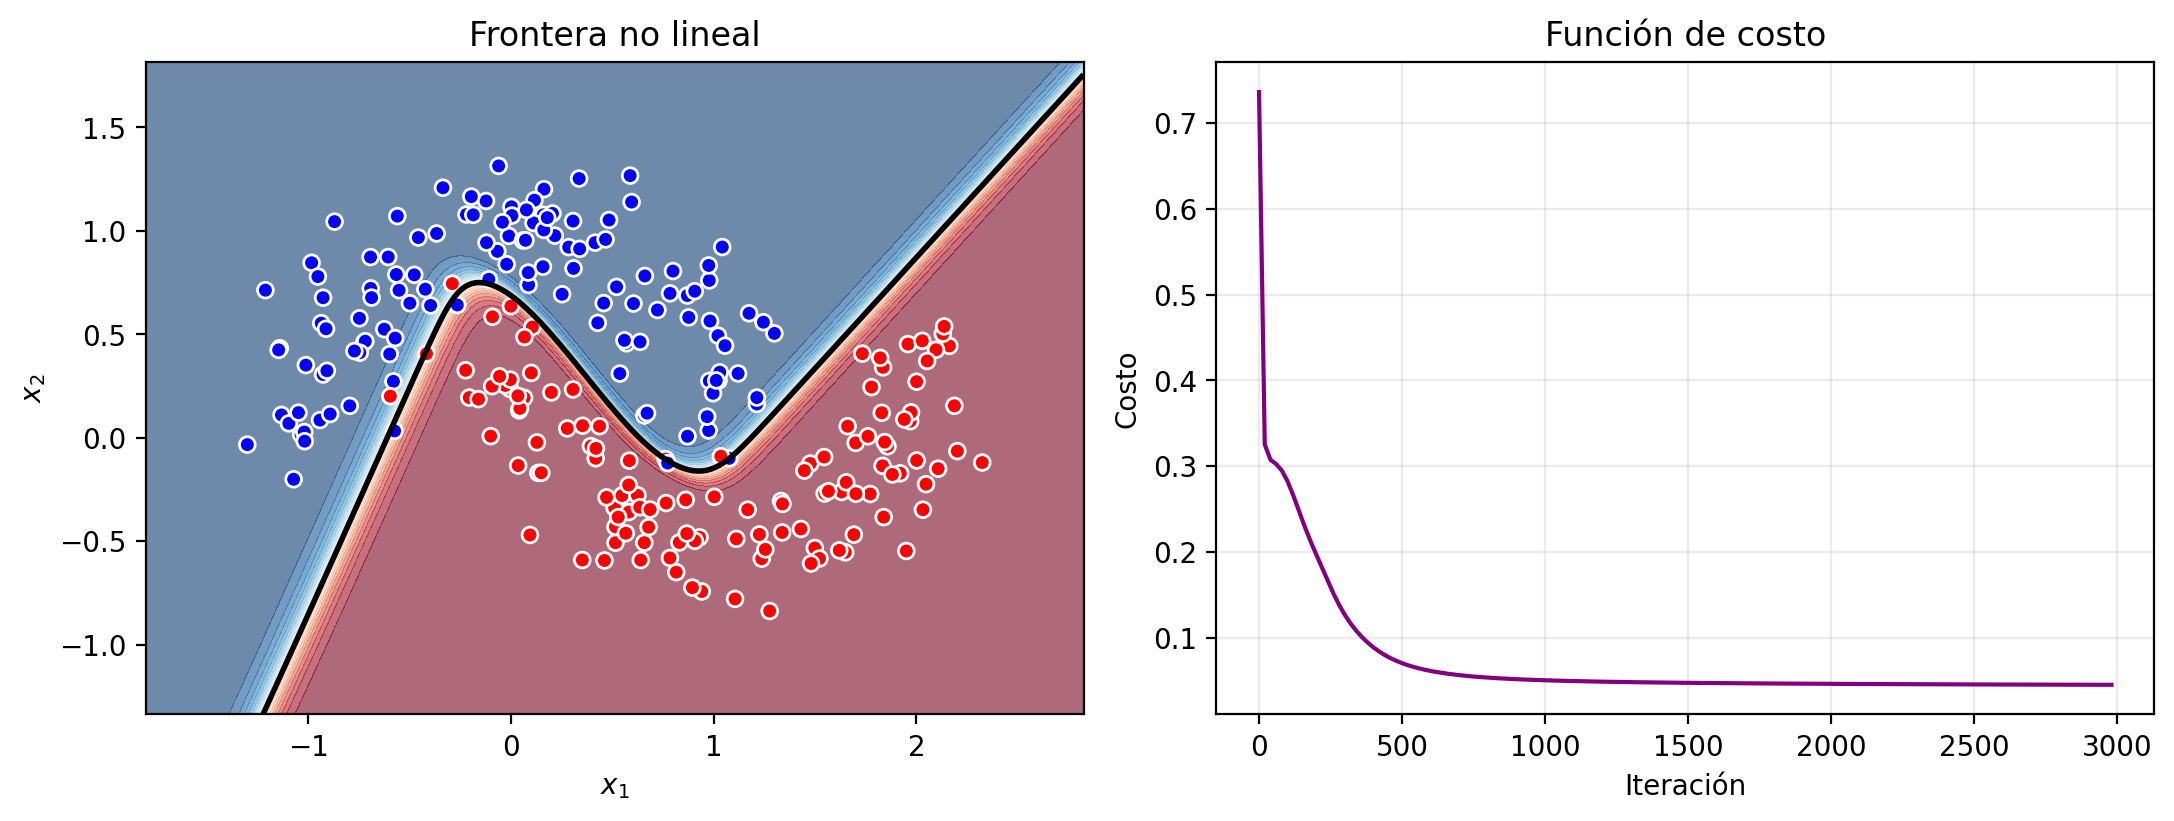

In [ ]:
eje_x1 = np.linspace(X[0].min() - 0.5, X[0].max() + 0.5, 220)
eje_x2 = np.linspace(X[1].min() - 0.5, X[1].max() + 0.5, 220)
malla_x1, malla_x2 = np.meshgrid(eje_x1, eje_x2)
X_malla = np.vstack((malla_x1.ravel(), malla_x2.ravel()))
A_malla, _cache_malla = forward_propagation(
    X_malla, parameters, activacion.value
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].contourf(
    malla_x1, malla_x2,
    A_malla.reshape(malla_x1.shape),
    levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.6,
)
axes[0].contour(
    malla_x1, malla_x2,
    A_malla.reshape(malla_x1.shape),
    levels=[0.5], colors="black", linewidths=2,
)
axes[0].scatter(
    X[0], X[1], c=y.ravel(),
    cmap=ListedColormap(["blue", "red"]), edgecolor="white", s=32,
)
axes[0].set(title="Frontera no lineal", xlabel="$x_1$", ylabel="$x_2$")

pasos, valores = zip(*costs)
axes[1].plot(pasos, valores, color="purple")
axes[1].set(title="Función de costo", xlabel="Iteración", ylabel="Costo")
axes[1].grid(alpha=0.25)
fig.tight_layout()
fig

In [ ]:
mo.callout(
    mo.md(
        f"""
        **Exactitud: {accuracy:.1%}**

        La activación oculta utilizada es `{activacion.value}`. Observa que
        ahora `A1.shape = {cache['A1'].shape}`: cada fila contiene la salida
        de una neurona oculta para todas las observaciones.

        Los parámetros aprendidos tienen formas
        `W1={parameters['W1'].shape}` y `W2={parameters['W2'].shape}`.
        """
    ),
    kind="success" if accuracy >= 0.85 else "warn",
)

<marimo-callout-output data-html='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003e\u003cstrong\u003eExactitud: 97.2%\u003c/strong\u003e\u003c/span\u003e\n\u003cspan class=\"paragraph\"\u003eLa activación oculta utilizada es \u003ccode\u003etanh\u003c/code\u003e. Observa que\nahora \u003ccode\u003eA1.shape = (4, 250)\u003c/code\u003e: cada fila contiene la salida\nde una neurona oculta para todas las observaciones.\u003c/span\u003e\n\u003cspan class=\"paragraph\"\u003eLos parámetros aprendidos tienen formas\n\u003ccode\u003eW1=(4, 2)\u003c/code\u003e y \u003ccode\u003eW2=(1, 4)\u003c/code\u003e.\u003c/span\u003e\u003c/span\u003e"' data-kind='"success"'>

## ¿Por qué necesitamos una función de activación?

Si reemplazamos $A^{[1]}=g(Z^{[1]})$ por $A^{[1]}=Z^{[1]}$, entonces:

$$Z^{[2]}=W^{[2]}W^{[1]}X+W^{[2]}b^{[1]}+b^{[2]}$$

Podemos agrupar los términos anteriores en una nueva matriz $W'$ y un nuevo
sesgo $b'$. Es decir, varias capas lineales siguen siendo equivalentes a una
sola capa lineal. La activación es la que permite construir una representación
no lineal.

### Preguntas

1. Entrena la red con una sola neurona oculta y después con cuatro.
2. Compara `tanh` y `ReLU` manteniendo los demás controles constantes.
3. Identifica qué configuraciones corresponden a falta de capacidad y cuáles a
   dificultades de optimización.

## Respuestas

Para comparar con las mismas condiciones no usé los controles de arriba, sino celdas con
valores fijos. Uso las funciones del propio notebook y los valores por defecto: las dos lunas
con ruido 0.18 y semilla 42, learning rate 0.8, 3000 iteraciones y la inicialización con
semilla 42 de `initialize_parameters`. Solo cambio el parámetro que quiero estudiar.

In [ ]:
def tabla_md(filas):
    """
    Argumentos:
    filas -- lista de diccionarios (una fila por diccionario)

    Retorna:
    texto de una tabla en markdown, para que se vea igual en marimo, Jupyter y GitHub
    """
    columnas = list(filas[0].keys())
    lineas = ["| " + " | ".join(columnas) + " |", "|" + "---|" * len(columnas)]
    for f in filas:
        lineas.append("| " + " | ".join(str(f[c]) for c in columnas) + " |")
    return "\n".join(lineas)

In [ ]:
_m, _e = make_moons(n_samples=250, noise=0.18, random_state=42)
X_exp, y_exp = _m.T, _e.reshape(1, -1)

def entrenar(n_h=4, nombre="tanh", learning_rate=0.8, iteraciones=3000, semilla=42):
    """
    Entrena la red con una capa oculta usando las funciones del notebook.
    Es el mismo ciclo de nn_model, pero permite cambiar la semilla de inicialización.

    Argumentos:
    n_h -- número de neuronas ocultas
    nombre -- activación oculta ("tanh" o "relu")
    learning_rate -- tasa de aprendizaje
    iteraciones -- número de actualizaciones
    semilla -- semilla de initialize_parameters

    Retorna:
    exactitud, costo final y parámetros entrenados
    """
    p = initialize_parameters(X_exp.shape[0], n_h, 1, nombre, semilla)
    for _i in range(iteraciones):
        a2, cache_e = forward_propagation(X_exp, p, nombre)
        p = update_parameters(p, backward_propagation(X_exp, y_exp, p, cache_e, nombre), learning_rate)
    a2, _c = forward_propagation(X_exp, p, nombre)
    a2_seg = np.clip(a2, 1e-10, 1 - 1e-10)
    costo = float(-np.mean(y_exp * np.log(a2_seg) + (1 - y_exp) * np.log(1 - a2_seg)))
    return float(np.mean((a2 > 0.5) == y_exp)), costo, p

### 1. Una neurona oculta contra cuatro

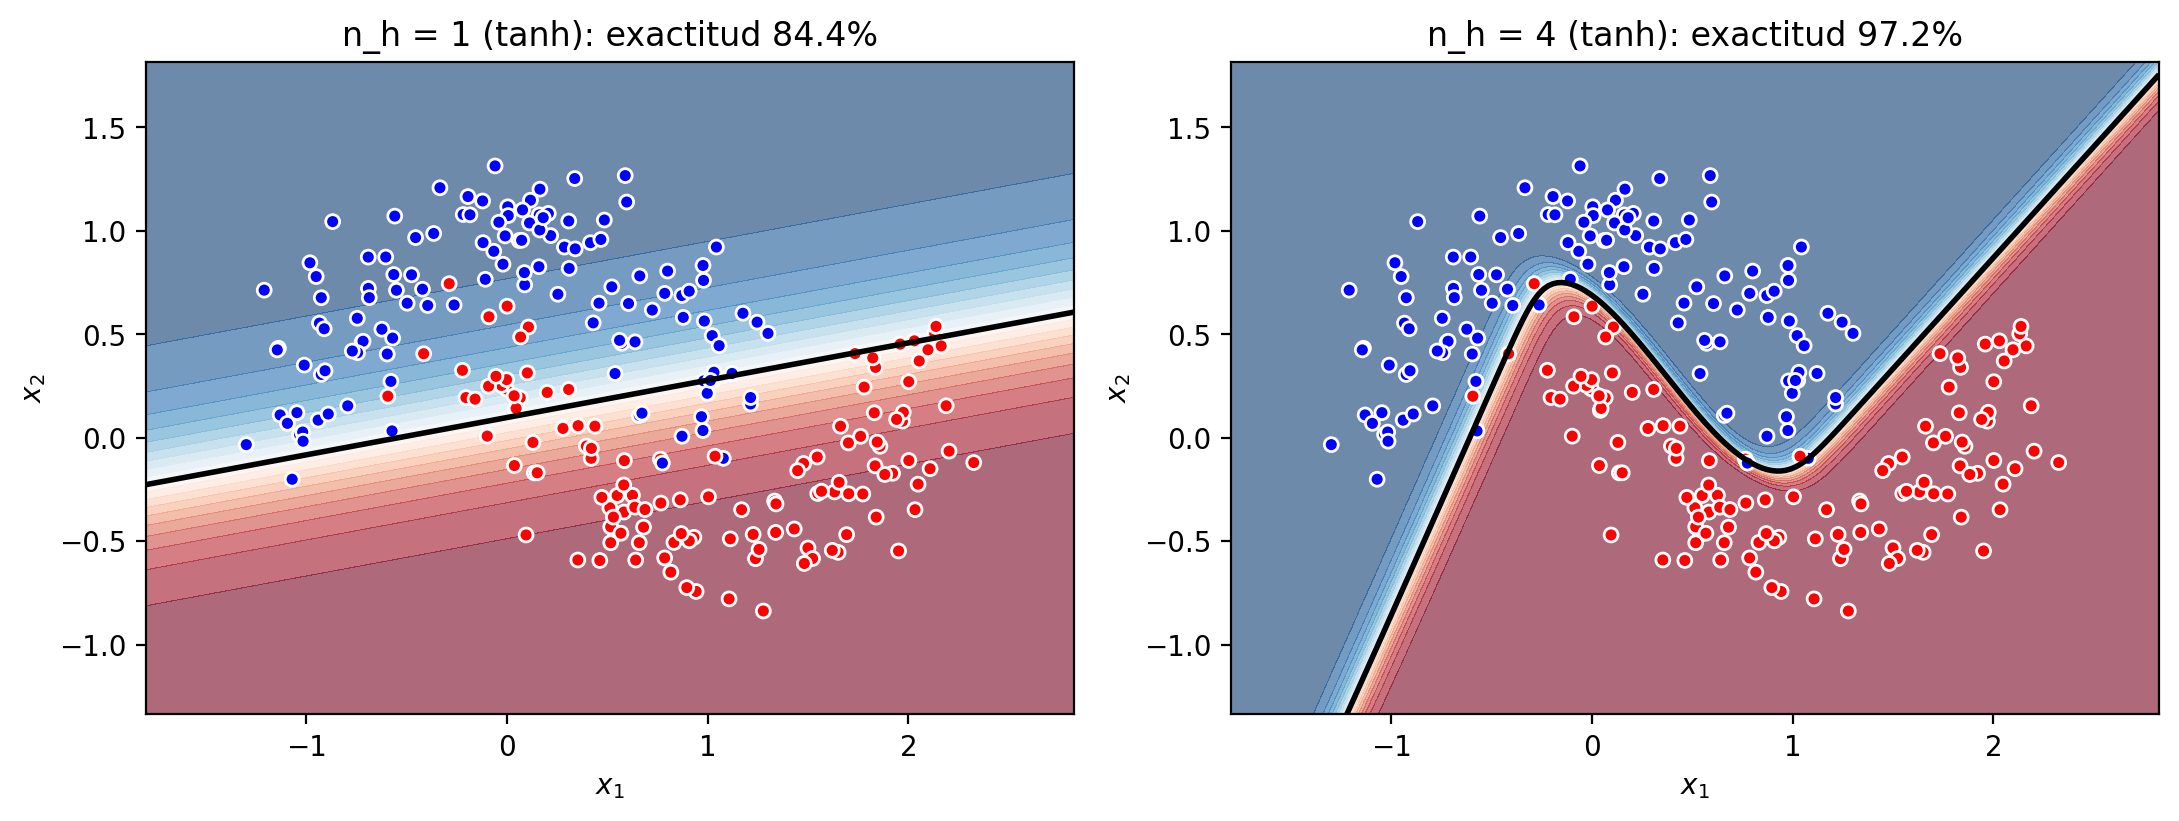

In [ ]:
casos_1 = [(1, "tanh"), (4, "tanh")]
res_1 = {c: entrenar(n_h=c[0], nombre=c[1]) for c in casos_1}
_g1, _g2 = np.meshgrid(np.linspace(X_exp[0].min() - 0.5, X_exp[0].max() + 0.5, 200),
                       np.linspace(X_exp[1].min() - 0.5, X_exp[1].max() + 0.5, 200))
_malla = np.vstack((_g1.ravel(), _g2.ravel()))
fig_1, ax_1 = plt.subplots(1, 2, figsize=(11, 4.2))
for _ax, _c in zip(ax_1, casos_1):
    _acc, _cost, _p = res_1[_c]
    _a, _ = forward_propagation(_malla, _p, _c[1])
    _a = _a.reshape(_g1.shape)
    _ax.contourf(_g1, _g2, _a, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.6)
    _ax.contour(_g1, _g2, _a, levels=[0.5], colors="black", linewidths=2)
    _ax.scatter(X_exp[0], X_exp[1], c=y_exp.ravel(), cmap=ListedColormap(["blue", "red"]),
                edgecolor="white", s=25)
    _ax.set(title=f"n_h = {_c[0]} ({_c[1]}): exactitud {_acc:.1%}", xlabel="$x_1$", ylabel="$x_2$")
fig_1.tight_layout()
fig_1

In [ ]:
mo.md(rf"""
Con una sola neurona oculta la exactitud es de {res_1[(1, "tanh")][0]:.1%} y con cuatro sube a
{res_1[(4, "tanh")][0]:.1%}. La diferencia se ve en la gráfica: con una neurona la frontera sigue
siendo una recta, y con cuatro ya se dobla siguiendo la forma de las lunas.

Que con una neurona salga una recta tiene una explicación sencilla. La salida es
$\sigma(w^{{[2]}} \tanh(z^{{[1]}}) + b^{{[2]}})$, y como $\tanh$ y $\sigma$ siempre crecen, la salida
pasa de 0.5 justo cuando $z^{{[1]}}$ cruza un valor fijo. Como $z^{{[1]}} = w_1 x_1 + w_2 x_2 + b$, eso
vuelve a ser una recta. O sea, una red con una neurona oculta no puede hacer más que el
perceptrón de la actividad anterior. Con cuatro neuronas, en cambio, la salida combina cuatro
rectas distintas y por eso la frontera puede curvarse.
""")

Con una sola neurona oculta la exactitud es de 84.4% y con cuatro sube a
97.2%. La diferencia se ve en la gráfica: con una neurona la frontera sigue
siendo una recta, y con cuatro ya se dobla siguiendo la forma de las lunas.

Que con una neurona salga una recta tiene una explicación sencilla. La salida es
$\sigma(w^{[2]} \tanh(z^{[1]}) + b^{[2]})$, y como $\tanh$ y $\sigma$ siempre crecen, la salida
pasa de 0.5 justo cuando $z^{[1]}$ cruza un valor fijo. Como $z^{[1]} = w_1 x_1 + w_2 x_2 + b$, eso
vuelve a ser una recta. O sea, una red con una neurona oculta no puede hacer más que el
perceptrón de la actividad anterior. Con cuatro neuronas, en cambio, la salida combina cuatro
rectas distintas y por eso la frontera puede curvarse.

### 2. `tanh` contra `ReLU`

In [ ]:
filas_2 = []
for _n in [1, 2, 3, 4, 8, 12]:
    _t = entrenar(n_h=_n, nombre="tanh")
    _r = entrenar(n_h=_n, nombre="relu")
    filas_2.append({"Neuronas ocultas": _n,
                    "tanh: exactitud / costo": f"{_t[0]:.1%} / {_t[1]:.4f}",
                    "ReLU: exactitud / costo": f"{_r[0]:.1%} / {_r[1]:.4f}"})
mo.md(tabla_md(filas_2))

| Neuronas ocultas | tanh: exactitud / costo | ReLU: exactitud / costo |
|---|---|---|
| 1 | 84.4% / 0.3124 | 85.6% / 0.2996 |
| 2 | 85.2% / 0.2698 | 88.0% / 0.2519 |
| 3 | 96.8% / 0.0452 | 87.2% / 0.2515 |
| 4 | 97.2% / 0.0450 | 98.0% / 0.0464 |
| 8 | 97.2% / 0.0437 | 97.2% / 0.0412 |
| 12 | 97.2% / 0.0438 | 97.6% / 0.0397 |

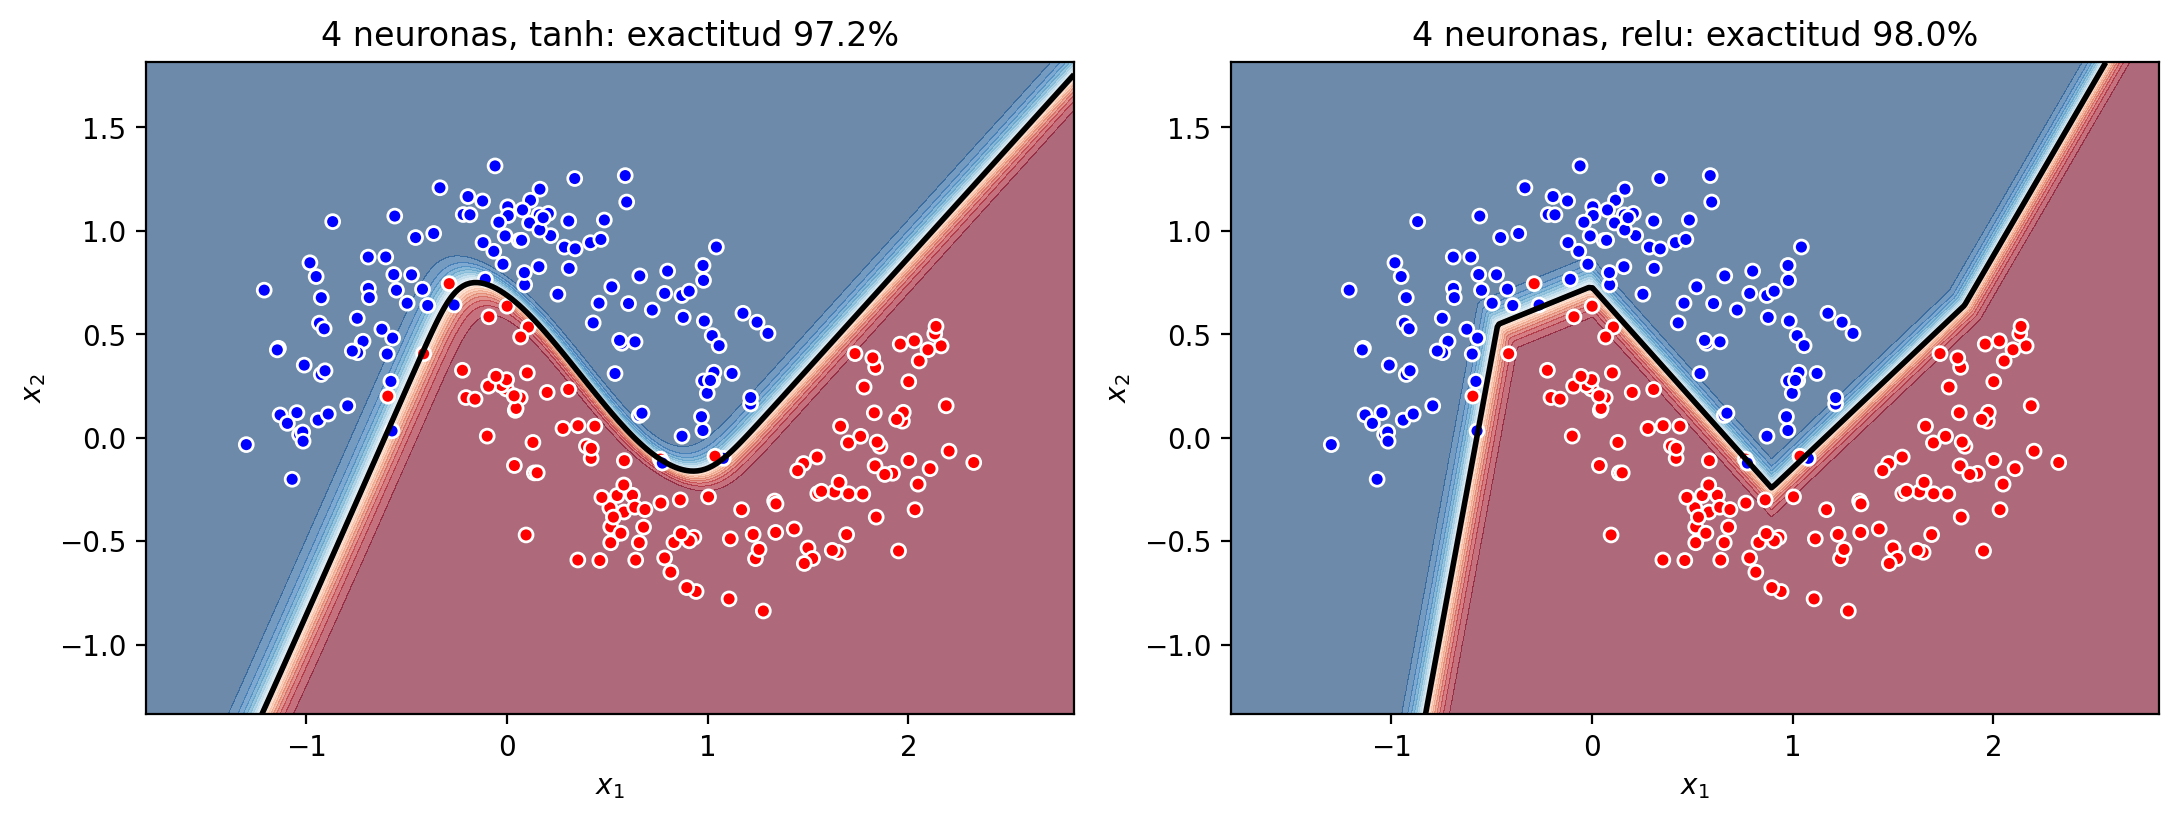

In [ ]:
# misma arquitectura (4 neuronas), solo cambia la activación
_g1, _g2 = np.meshgrid(np.linspace(X_exp[0].min() - 0.5, X_exp[0].max() + 0.5, 250),
                       np.linspace(X_exp[1].min() - 0.5, X_exp[1].max() + 0.5, 250))
_malla = np.vstack((_g1.ravel(), _g2.ravel()))
fig_2, ax_2 = plt.subplots(1, 2, figsize=(11, 4.2))
for _ax, _act in zip(ax_2, ["tanh", "relu"]):
    _acc, _cost, _p = entrenar(n_h=4, nombre=_act)
    _a, _ = forward_propagation(_malla, _p, _act)
    _a = _a.reshape(_g1.shape)
    _ax.contourf(_g1, _g2, _a, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.6)
    _ax.contour(_g1, _g2, _a, levels=[0.5], colors="black", linewidths=2)
    _ax.scatter(X_exp[0], X_exp[1], c=y_exp.ravel(), cmap=ListedColormap(["blue", "red"]),
                edgecolor="white", s=25)
    _ax.set(title=f"4 neuronas, {_act}: exactitud {_acc:.1%}", xlabel="$x_1$", ylabel="$x_2$")
fig_2.tight_layout()
fig_2

Con los valores por defecto (cuatro neuronas) las dos funcionan casi igual: 97.2 % con `tanh` y
98.0 % con `ReLU`, y el costo final es prácticamente el mismo. Donde sí se nota la diferencia es
en la forma de la frontera. Con `tanh` la curva es suave, porque $\tanh$ cambia de manera
gradual. Con `ReLU` la frontera se arma con tramos rectos que se quiebran en esquinas, porque
cada neurona vale cero de un lado de su recta y crece en línea recta del otro; sumar varias de
esas funciones da algo que se dobla por partes, no una curva.

En la tabla también aparece una diferencia con tres neuronas: `tanh` llega a 96.8 % y `ReLU`
se queda en 87.2 %. Al principio pensé que era porque a `ReLU` le hacían falta más neuronas,
pero en la pregunta 3 vi que no es así: con otra inicialización, `ReLU` con tres neuronas llega
a 97 %. Con `ReLU` el resultado depende más del punto de partida, porque una neurona que queda
en cero para casi todos los puntos deja de recibir gradiente de ese lado. Con ocho o doce
neuronas las dos quedan alrededor de 97 %, así que en este problema la activación cambia sobre
todo la forma de la frontera y qué tan estable es el entrenamiento, no qué tan bien clasifica.

### 3. Falta de capacidad contra dificultades de optimización

Para separar los dos casos me fijé en una sola cosa: si al darle más iteraciones, otro
learning rate u otra inicialización el resultado mejora, el modelo sí podía resolverlo y el
problema era de optimización. Si no mejora con nada, le falta capacidad.

In [ ]:
configs_3 = [
    ("1 neurona, tanh, 3000 it.", dict(n_h=1)),
    ("1 neurona, tanh, 10000 it.", dict(n_h=1, iteraciones=10000)),
    ("1 neurona, tanh, lr 1.5", dict(n_h=1, learning_rate=1.5)),
    ("4 neuronas, lr 0.01", dict(learning_rate=0.01)),
    ("4 neuronas, lr 0.05", dict(learning_rate=0.05)),
    ("4 neuronas, 200 it.", dict(iteraciones=200)),
    ("4 neuronas, 600 it.", dict(iteraciones=600)),
    ("4 neuronas, valores por defecto", dict()),
    ("3 neuronas, ReLU, semilla 42", dict(n_h=3, nombre="relu")),
    ("3 neuronas, ReLU, semilla 42, 10000 it.", dict(n_h=3, nombre="relu", iteraciones=10000)),
    ("3 neuronas, ReLU, semilla 2", dict(n_h=3, nombre="relu", semilla=2)),
    ("3 neuronas, ReLU, semilla 3", dict(n_h=3, nombre="relu", semilla=3)),
]
filas_3 = []
for _nombre, _kw in configs_3:
    _acc, _cost, _ = entrenar(**_kw)
    filas_3.append({"Configuración": _nombre, "Exactitud": f"{_acc:.1%}", "Costo final": f"{_cost:.4f}"})
mo.md(tabla_md(filas_3))

| Configuración | Exactitud | Costo final |
|---|---|---|
| 1 neurona, tanh, 3000 it. | 84.4% | 0.3124 |
| 1 neurona, tanh, 10000 it. | 84.4% | 0.3124 |
| 1 neurona, tanh, lr 1.5 | 84.8% | 0.3271 |
| 4 neuronas, lr 0.01 | 85.2% | 0.3079 |
| 4 neuronas, lr 0.05 | 92.8% | 0.2028 |
| 4 neuronas, 200 it. | 92.8% | 0.1969 |
| 4 neuronas, 600 it. | 97.2% | 0.0611 |
| 4 neuronas, valores por defecto | 97.2% | 0.0450 |
| 3 neuronas, ReLU, semilla 42 | 87.2% | 0.2515 |
| 3 neuronas, ReLU, semilla 42, 10000 it. | 87.2% | 0.2514 |
| 3 neuronas, ReLU, semilla 2 | 96.8% | 0.0475 |
| 3 neuronas, ReLU, semilla 3 | 97.2% | 0.0471 |

**Falta de capacidad.** La red con una sola neurona oculta (y en menor medida con dos). Con
una neurona da 84.4 % y se queda igual con 10,000 iteraciones; con learning rate 1.5 apenas se
mueve a 84.8 %. Es porque
ya encontró la mejor recta posible y, como expliqué en la pregunta 1, no puede hacer otra cosa
que una recta. Por más que se entrene, el modelo no tiene con qué representar la curva.

**Dificultades de optimización.** Aquí entran los casos donde la arquitectura sí alcanza,
pero el entrenamiento no llega:

- **Learning rate muy chico.** Con 0.01 y cuatro neuronas la red se queda en 85.2 %, casi igual
  que con una sola neurona. Si solo viera ese número pensaría que le falta capacidad, pero con
  0.05 ya sube a 92.8 % y con 0.8 llega a 97.2 %. La red podía; lo que faltaba era avanzar más
  rápido.
- **Pocas iteraciones.** Con 200 iteraciones va en 92.8 % y con 600 ya llega a 97.2 %.
- **Mala inicialización.** Este fue el caso que más me sorprendió. Con `ReLU` y tres neuronas, la
  inicialización con semilla 42 se queda en 87.2 %, y aunque le dé 10,000 iteraciones no se
  mueve. Parecería falta de capacidad, pero con la semilla 2 o la 3 la misma red llega a
  96.8 % y 97.2 %. Lo que pasa es que el entrenamiento cayó en un mínimo local: desde ese punto
  de partida no encuentra cómo mejorar, aunque exista una mejor solución.

Con esto me quedó claro que un resultado estancado no basta para concluir que le falta
capacidad al modelo. Hay que probar si cambiando la optimización (tasa, iteraciones,
inicialización) el resultado se mueve antes de cambiar la arquitectura.

### Comprobación: la red sin función de activación

Arriba, en la sección "¿Por qué necesitamos una función de activación?", se explica que sin
activación varias capas equivalen a una sola capa lineal. Quise comprobarlo, porque también es
un caso de falta de capacidad. Entrené la misma red de cuatro neuronas con $A^{[1]} = Z^{[1]}$, que
hace que la derivada de la activación valga 1.

In [ ]:
_p = initialize_parameters(2, 4, 1, "tanh", 42)
_m = X_exp.shape[1]

def _sig(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

for _i in range(3000):
    _A1 = _p["W1"] @ X_exp + _p["b1"]               # sin activación: A1 = Z1
    _A2 = _sig(_p["W2"] @ _A1 + _p["b2"])
    _dZ2 = _A2 - y_exp
    _dZ1 = _p["W2"].T @ _dZ2                        # la derivada de la identidad es 1
    _p["W2"] -= 0.8 * (_dZ2 @ _A1.T) / _m
    _p["b2"] -= 0.8 * np.sum(_dZ2, axis=1, keepdims=True) / _m
    _p["W1"] -= 0.8 * (_dZ1 @ X_exp.T) / _m
    _p["b1"] -= 0.8 * np.sum(_dZ1, axis=1, keepdims=True) / _m
_A2 = _sig(_p["W2"] @ (_p["W1"] @ X_exp + _p["b1"]) + _p["b2"])
exactitud_lineal = float(np.mean((_A2 > 0.5) == y_exp))
mo.md(rf"""
Con cuatro neuronas pero sin activación la exactitud es de **{exactitud_lineal:.1%}**, casi lo
mismo que con una sola neurona (84.4 %) y muy lejos del 97.2 % con `tanh`. Las cuatro neuronas
no sirven de nada si no hay activación, porque $W^{{[2]}}W^{{[1]}}$ se puede juntar en una sola
matriz y la frontera vuelve a ser una recta. Esto confirma que lo que le da capacidad a la red
no es solo el número de neuronas, sino la activación no lineal entre capas.
""")

Con cuatro neuronas pero sin activación la exactitud es de **85.6%**, casi lo
mismo que con una sola neurona (84.4 %) y muy lejos del 97.2 % con `tanh`. Las cuatro neuronas
no sirven de nada si no hay activación, porque $W^{[2]}W^{[1]}$ se puede juntar en una sola
matriz y la frontera vuelve a ser una recta. Esto confirma que lo que le da capacidad a la red
no es solo el número de neuronas, sino la activación no lineal entre capas.